# §2 Data profiling and quality audit

This part works out where the data can be trusted and turns each finding into a recorded decision. §2.1 re-checks provenance, the codebook-derived specification and minimisation; the audit follows in §3:

§3.1 XPT read artefact · §3.2 completeness and funnel · §3.3 sentinel map · §3.4 cost of a blanket recode · §3.5 consistency · §3.6 top-coding · §3.7 HbA1c missingness · §3.8 outliers · §3.9 quality matrix.

Key numbers are asserted against reference values from an independent earlier computation, so any drift fails loudly. Results go to `results/metrics_S2.json` / `metrics_S3.json` and `results/S3/`, decisions to `governance/register/S2.csv` / `S3.csv`.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from IPython.display import display

from src import nhanes_io as io

pd.set_option("display.width", 160, "display.max_colwidth", 70, "display.max_rows", 80)
OI = C.OKABE_ITO
OUT = C.RESULTS_DIR / "S3"
OUT.mkdir(parents=True, exist_ok=True)
(C.RESULTS_DIR / "S2").mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref",
                 "change_request", "commit"]
M2, M3 = {}, {}   # metrics stored for S2 and S3


def close(a, b, tol=0.0):
    """Assert helper: |a - b| <= tol."""
    return abs(float(a) - float(b)) <= tol


def write_register(stage, rows):
    reg = pd.DataFrame(rows)
    for c in REGISTER_COLS:
        if c not in reg:
            reg[c] = ""
    reg = reg[REGISTER_COLS]
    reg.to_csv(C.GOVERNANCE_DIR / "register" / f"{stage}.csv", index=False, lineterminator="\n")
    return reg

## 0 Provenance, specification and minimisation (Stage S2 checks)

**Why.** An audit is only as good as its inputs. Three things are checked before any profiling:

- the raw files are the unmodified CDC files (SHA-256 against `MANIFEST.sha256`);
- the variable specification `config/variable_spec.csv` agrees with the CDC codebooks and with the columns actually present in the XPT files, because every sentinel code must have a traceable source;
- the loader keeps only what the purpose needs (data minimisation, GDPR Art. 5(1)(c)).

In [2]:
integrity = io.ensure_raw_data(download=False)
print(f"raw files verified against MANIFEST.sha256: {len(integrity['verified'])}/{integrity['n_files']}; mismatched: {integrity['mismatched']}")
assert integrity["mismatched"] == [] and len(integrity["verified"]) == 16

spec = io.load_spec()
problems = io.verify_spec(spec)
print("verify_spec problems:", problems or "none")
assert problems == []

inc = io.included(spec)
role_tab = (inc[inc["var"] != "SEQN"].groupby(["role", "admissible"]).size().unstack(fill_value=0))
display(role_tab)
tier_tab = spec[spec["var"] != "SEQN"].groupby("use_tier").size().rename("variables").to_frame()
display(tier_tab)

min_files, min_cols = io.minimisation_report(spec)
min_files.to_csv(C.RESULTS_DIR / "S2" / "minimisation_report.csv", index=False, lineterminator="\n")
min_cols.to_csv(C.RESULTS_DIR / "S2" / "minimisation_columns.csv", index=False, lineterminator="\n")
display(min_files[["file", "use_tier", "rows", "cols_raw", "cols_kept", "cols_dropped"]])
n_raw, n_kept, n_drop = (int(min_files[c].sum()) for c in ("cols_raw", "cols_kept", "cols_dropped"))
print(f"columns: raw {n_raw}, kept {n_kept}, dropped {n_drop}; every dropped column has a reason:",
      bool(min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()))
assert n_raw == len(spec) == 175 and n_kept + n_drop == n_raw
assert min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()

n_sentinel_vars = len(io.sentinel_map(spec))
cont_inc = inc[(inc["dtype"] == "continuous") & inc["file"].isin(["BMX_L", "BPXO_L", "GHB_L", "TCHOL_L", "HDL_L", "GLU_L", "TRIGLY_L"])]
print(f"included variables with codebook refusal/don't-know codes: {n_sentinel_vars}; "
      f"continuous lab/exam measures with such codes: {int((cont_inc['sentinel_codes'] != '').sum())} of {len(cont_inc)}")
assert (cont_inc["sentinel_codes"] == "").all() and len(cont_inc) == 21 and n_sentinel_vars == 25

raw files verified against MANIFEST.sha256: 16/16; mismatched: []


verify_spec problems: none


admissible,N,T1,T2
role,,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
feature,0,30,2
label,2,0,0
leak,8,0,0
optional,5,0,0
redundancy,2,0,0
side,2,0,0


,variables
use_tier,
core,41
excluded,97
optional,5
recommended,10
redundancy_demo,2
side_analysis,4


,file,use_tier,rows,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,11933,27,13,14
1,GHB_L,core,7199,3,3,0
2,GLU_L,side_analysis,3996,4,3,1
3,BMX_L,core,8860,22,7,15
4,BPXO_L,core,7801,12,10,2
5,TCHOL_L,core,8068,4,2,2
6,HDL_L,core,8068,4,2,2
7,TRIGLY_L,side_analysis,3996,10,3,7
8,DIQ_L,core,11744,9,9,0
9,BPQ_L,recommended,8501,6,3,3


columns: raw 175, kept 78, dropped 97; every dropped column has a reason: True
included variables with codebook refusal/don't-know codes: 25; continuous lab/exam measures with such codes: 0 of 21


**So what.** All 16 raw files match their hashes (CDC public-use files, Aug 2021 – Aug 2023, downloaded 2026-10-10). The specification has one row per raw column (175) and agrees with the codebooks and XPT headers; the loader keeps 78 columns and drops 97, each with a reason. The 25 variables with refusal or don't-know codes are all questionnaire items; none of the 21 continuous measures has one (§3.4 shows why this matters).

In [3]:
M2.update({
    "raw_files_verified": len(integrity["verified"]), "hash_mismatches": len(integrity["mismatched"]),
    "spec_rows": len(spec), "spec_problems": len(problems),
    "minimisation": {"cols_raw": n_raw, "cols_kept": n_kept, "cols_dropped": n_drop,
                     "per_file": min_files.set_index("file")[["cols_raw", "cols_kept", "cols_dropped"]].to_dict("index")},
    "use_tier_counts": tier_tab["variables"].to_dict(),
    "role_admissible": {f"{r}|{a}": int(v) for (r, a), v in role_tab.stack().items() if v},
    "n_sentinel_variables": n_sentinel_vars,
})

## 1 XPT read artefact and zero-weight semantics

**Why.** pandas reads a stored XPT zero as 5.397605e-79 (= 16⁻⁶⁵), a reader artefact that creates a spurious minimum and breaks `== 0` tests ("zero weight", "no activity"). The repair must keep NaN as NaN; the tempting `x.where(|x| >= 1e-10, 0)` turns every NaN into 0.

In [4]:
art = io.xpt_artefact_audit()
art_file = art.groupby("file")["n_artefact"].sum().reindex(C.NHANES_FILES)
art_vars = art[art["n_artefact"] > 0].sort_values(["file", "n_artefact"], ascending=[True, False])
display(art_vars.reset_index(drop=True))
n_art = int(art_file.sum())
files_hit = art_file[art_file > 0].index.tolist()
print(f"artefact cells: {n_art:,} in {len(files_hit)} files")
print("  affected:", ", ".join(files_hit))
print("  clean:   ", ", ".join(art_file[art_file == 0].index))
art.to_csv(OUT / "xpt_artefacts.csv", index=False, lineterminator="\n")

# demonstrate the NaN-preservation requirement on one affected file
paq = io.read_xpt("PAQ_L")
fixed, n_fixed = io.fix_xpt(paq)
num = paq.select_dtypes("number")
wrong = num.where(num.abs() >= C.XPT_ZERO_EPS, 0.0)   # the tempting `where` version: NaN fails the test -> 0
nan_before, nan_after, nan_wrong = int(num.isna().sum().sum()), int(fixed[num.columns].isna().sum().sum()), int(wrong.isna().sum().sum())
residual = int(io._artefact_mask(fixed).to_numpy().sum())
print(f"PAQ_L: fixed {n_fixed:,} cells; NaN before {nan_before:,}, after mask-fix {nan_after:,}, after where-fix {nan_wrong:,}; residual 0<|x|<1e-10: {residual}")
assert nan_after == nan_before and residual == 0 and nan_wrong < nan_before

# whole-project check: all files repaired, NaN count unchanged
tot_fixed = 0
for f in C.NHANES_FILES:
    raw = io.read_xpt(f)
    fx, k = io.fix_xpt(raw)
    tot_fixed += k
    assert io._artefact_mask(fx).to_numpy().sum() == 0
    assert fx.select_dtypes("number").isna().sum().sum() == raw.select_dtypes("number").isna().sum().sum()
assert n_art == tot_fixed == 13676 and len(files_hit) == 9

,file,var,n_artefact
0,DEMO_L,WTMEC2YR,3073
1,DEMO_L,RIDAGEYR,189
2,DEMO_L,INDFMPIR,100
3,DEMO_L,RIDAGEMN,17
4,DEMO_L,RIDEXAGM,4
5,GHB_L,WTPH2YR,449
6,GLU_L,WTSAF2YR,635
7,HDL_L,WTPH2YR,752
8,INQ_L,INDFMMPI,218
9,PAQ_L,PAD810Q,4413


artefact cells: 13,676 in 9 files
  affected: DEMO_L, GHB_L, GLU_L, TCHOL_L, HDL_L, TRIGLY_L, INQ_L, SMQ_L, PAQ_L
  clean:    BMX_L, BPXO_L, DIQ_L, BPQ_L, MCQ_L, HIQ_L, HUQ_L
PAQ_L: fixed 6,117 cells; NaN before 6,276, after mask-fix 6,276, after where-fix 0; residual 0<|x|<1e-10: 0


Several of the repaired zeros have a meaning defined in the codebook. A zero weight marks a participant outside that weight's sub-sample, so it must become missing before any weighted calculation:

In [5]:
demo = io.load_file("DEMO_L", minimise=False)[0]
ghb = io.load_file("GHB_L", minimise=False)[0]
glu = io.load_file("GLU_L", minimise=False)[0]
zw = pd.DataFrame([
    ["WTMEC2YR = 0", int((demo["WTMEC2YR"] == 0).sum()), "not MEC-examined", int((demo["RIDSTATR"] == 1).sum())],
    ["WTPH2YR = 0 (GHB_L)", int((ghb["WTPH2YR"] == 0).sum()), "no blood sample provided", None],
    ["WTSAF2YR = 0 (GLU_L)", int((glu["WTSAF2YR"] == 0).sum()), "fasting sub-sample non-response", None],
], columns=["condition", "n", "codebook meaning", "cross-check: RIDSTATR = 1 (interview only)"])
display(zw)
coh = io.build_cohort()
zero_in_cohort = int((coh["WTPH2YR"] == 0).sum())
print(f"cohort rows with WTPH2YR = 0: {zero_in_cohort}; WTPH2YR missing: {int(coh['WTPH2YR'].isna().sum())}")
assert zw.loc[0, "n"] == 3073 == zw.loc[0, "cross-check: RIDSTATR = 1 (interview only)"]
assert zw.loc[1, "n"] == 449 and zero_in_cohort == 0

,condition,n,codebook meaning,cross-check: RIDSTATR = 1 (interview only)
0,WTMEC2YR = 0,3073,not MEC-examined,3073.0
1,WTPH2YR = 0 (GHB_L),449,no blood sample provided,NaN
2,WTSAF2YR = 0 (GLU_L),635,fasting sub-sample non-response,NaN


cohort rows with WTPH2YR = 0: 0; WTPH2YR missing: 0


**So what.** The artefact affects 13,676 cells in 9 files, mostly weights or frequencies whose true value is 0 (3,073 zero exam weights, 4,413 zero vigorous-activity sessions); the `mask` repair keeps every NaN, and no value with 0 < |x| < 10⁻¹⁰ remains. The zero weights carry meaning: `WTMEC2YR = 0` marks exactly the interview-only participants and `WTPH2YR = 0` the 449 without a blood sample. **Decision (DR-S3-01):** repair with `mask` at load time; zero weights become NaN before any weighted analysis.

In [6]:
M3["xpt_artefact"] = {"cells": n_art, "files": files_hit, "n_files": len(files_hit),
                      "per_file": {k: int(v) for k, v in art_file.items() if v},
                      "paq_nan_before": nan_before, "paq_nan_after_mask": nan_after, "paq_nan_after_where": nan_wrong}
M3["zero_weights"] = {"WTMEC2YR_0": int(zw.loc[0, "n"]), "WTPH2YR_0": int(zw.loc[1, "n"]),
                      "WTSAF2YR_0": int(zw.loc[2, "n"]), "cohort_WTPH2YR_0": zero_in_cohort}

## 2 Completeness, uniqueness and the sample funnel

**Why.** A left join on `SEQN` is only safe if `SEQN` is unique in every file and every file's participants are a subset of `DEMO_L`. Otherwise rows are duplicated or silently lost. The cohort definition is the first measurement decision of the project. Its funnel is asserted so that a change in any step fails loudly.

,file,rows,seqn_unique,subset_of_DEMO
0,DEMO_L,11933,True,True
1,GHB_L,7199,True,True
2,GLU_L,3996,True,True
3,BMX_L,8860,True,True
4,BPXO_L,7801,True,True
5,TCHOL_L,8068,True,True
6,HDL_L,8068,True,True
7,TRIGLY_L,3996,True,True
8,DIQ_L,11744,True,True
9,BPQ_L,8501,True,True


,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


cohort N = 5,730; RIDEXPRG = 3 (cannot ascertain) kept and flagged: 21


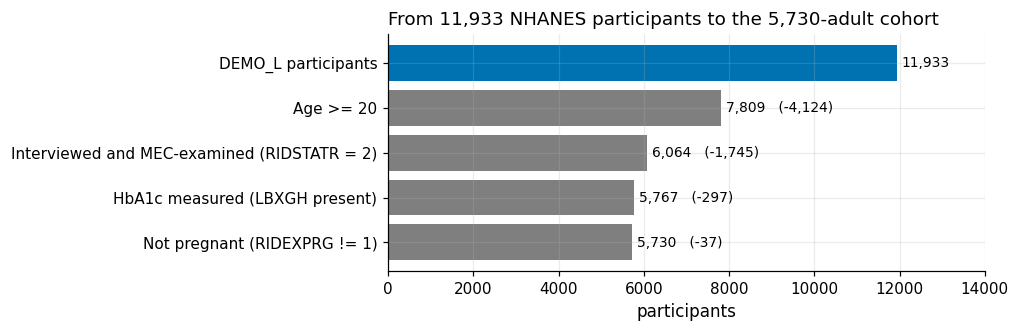

saved figures/S3_funnel.png


In [7]:
uniq = []
demo_ids = set(demo["SEQN"])
for f in C.NHANES_FILES:
    ids = io.read_xpt(f)["SEQN"]
    uniq.append({"file": f, "rows": len(ids), "seqn_unique": ids.is_unique, "subset_of_DEMO": set(ids) <= demo_ids})
uniq = pd.DataFrame(uniq)
display(uniq)
assert uniq["seqn_unique"].all() and uniq["subset_of_DEMO"].all()

fun = io.funnel()
display(fun)
assert tuple(fun["n"]) == io.FUNNEL_EXPECTED
preg3 = int(coh["preg_unknown"].sum())
print(f"cohort N = {len(coh):,}; RIDEXPRG = 3 (cannot ascertain) kept and flagged: {preg3}")
assert preg3 == 21

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(fun["step"][::-1], fun["n"][::-1], color=[OI["grey"]] * 4 + [OI["blue"]])
for y, (n, d) in enumerate(zip(fun["n"][::-1], fun["dropped"][::-1])):
    ax.text(n + 120, y, f"{n:,}" + (f"   (-{d:,})" if d else ""), va="center", fontsize=9)
ax.set_xlabel("participants"); ax.set_xlim(0, 14000)
ax.set_title("From 11,933 NHANES participants to the 5,730-adult cohort", loc="left")
f_funnel = plots.savefig(fig, "S3_funnel", caption="Sample funnel: DEMO_L participants -> age >= 20 -> interviewed and examined -> HbA1c measured -> not pregnant (N = 5,730). Numbers in brackets are the rows removed at each step.")
plt.show(); print("saved", f_funnel)

**So what.** `SEQN` is unique in all 16 files and each is a subset of `DEMO_L`, so the join neither duplicates nor drops anyone. Funnel: 11,933 → 7,809 (age ≥ 20) → 6,064 (examined) → 5,767 (HbA1c present) → 5,730 (not pregnant); the examination step loses most (1,745). The 297 examined adults without HbA1c are studied in §3.7; 21 women with unascertainable pregnancy status are kept and flagged.

In [8]:
M3["funnel"] = dict(zip(fun["step"], fun["n"].astype(int)))
M3["uniqueness"] = {"files_seqn_unique": int(uniq["seqn_unique"].sum()), "files_subset_of_demo": int(uniq["subset_of_DEMO"].sum())}
M3["preg_unknown_kept"] = preg3

## 3 Per-variable sentinel map

**Why.** NHANES codes "Refused" / "Don't know" differently per variable (7/9, 77/99, 777/999, 7777/9999), and continuous measures have no such codes at all, so the sentinel map comes from each variable's codebook entry. Two checks make it auditable: recoded rows must equal the codebook frequency of each code, and look-alike codes that are real categories (`DIQ010 = 3` borderline, `HUQ030 = 3` more than one place of care) are kept.

In [9]:
cb = io.codebook_table()
rows = []
for f in C.NHANES_FILES:
    part = io.load_file(f, spec=spec)[0]
    _, aud = io.apply_sentinels(part, spec, mode="per_variable")
    for _, a in aud.iterrows():
        codes = io._codes(a["codes"])
        cbv = cb[(cb["file"] == f) & (cb["var"] == a["var"])]
        cb_rows = cbv[cbv["code"].isin([str(c) for c in codes])]
        rows.append({"var": a["var"], "file": f, "codes": a["codes"],
                     "codebook_desc": " / ".join(cb_rows["desc"]),
                     "codebook_count": int(cb_rows["count"].sum()),
                     "recoded_file": int(a["n_recoded"])})
sent = pd.DataFrame(rows)
_, aud_coh = io.apply_sentinels(io.build_cohort(sentinels="none"), spec, mode="per_variable")
sent = sent.merge(aud_coh[["var", "n_recoded"]].rename(columns={"n_recoded": "recoded_cohort"}), on="var", how="left")
sent["traceable"] = sent["codebook_count"] == sent["recoded_file"]
display(sent)
sent.to_csv(OUT / "sentinel_audit.csv", index=False, lineterminator="\n")
assert sent["traceable"].all(), sent[~sent["traceable"]]
assert len(sent) == 25 and int(sent["recoded_file"].sum()) == 1047
assert sent["codebook_desc"].str.split(" / ").map(lambda d: all(x in ("Refused", "Don't know") for x in d)).all()

legit = pd.DataFrame([
    ["DIQ010 = 3", "Borderline", int((coh["DIQ010"] == 3).sum()), int((io.read_xpt("DIQ_L")["DIQ010"] == 3).sum())],
    ["HUQ030 = 3", "There is more than one place", int((coh["HUQ030"] == 3).sum()), int((io.read_xpt("HUQ_L")["HUQ030"] == 3).sum())],
    ["RIDRETH3 = 7", "Other race, including multi-racial", int((coh["RIDRETH3"] == 7).sum()), int((demo["RIDRETH3"] == 7).sum())],
], columns=["code", "meaning", "cohort", "file"])
display(legit)
assert legit.loc[0, "cohort"] == 213 and legit.loc[0, "file"] == 284
n_sent_coh = int(sent["recoded_cohort"].fillna(0).sum())
print(f"variables with codebook sentinels: {len(sent)}; cells recoded in the files: {int(sent['recoded_file'].sum()):,}; in the cohort: {n_sent_coh:,}")

,var,file,codes,codebook_desc,codebook_count,recoded_file,recoded_cohort,traceable
0,DMDEDUC2,DEMO_L,7;9,Refused / Don't know,11,11,2,True
1,DMDMARTZ,DEMO_L,77;99,Refused / Don't know,9,9,4,True
2,DIQ010,DIQ_L,7;9,Refused / Don't know,4,4,0,True
3,DID040,DIQ_L,777;999,Refused / Don't know,24,24,14,True
4,DIQ160,DIQ_L,7;9,Refused / Don't know,15,15,8,True
5,DIQ180,DIQ_L,7;9,Refused / Don't know,267,267,173,True
6,DIQ050,DIQ_L,7;9,Refused / Don't know,0,0,0,True
7,DID060,DIQ_L,777;999,Refused / Don't know,8,8,6,True
8,DIQ070,DIQ_L,7;9,Refused / Don't know,7,7,4,True
9,BPQ020,BPQ_L,7;9,Refused / Don't know,11,11,4,True


,code,meaning,cohort,file
0,DIQ010 = 3,Borderline,213,284
1,HUQ030 = 3,There is more than one place,34,57
2,RIDRETH3 = 7,"Other race, including multi-racial",363,948


variables with codebook sentinels: 25; cells recoded in the files: 1,047; in the cohort: 562


**So what.** For all 25 variables the recoded rows equal the codebook frequencies (1,047 cells; 562 in the cohort, most for `DIQ180`). Look-alike categories stay untouched: 213 borderline answers, 34 people with more than one usual place of care and 363 multiracial adults (`RIDRETH3 = 7`). **Decision (DR-S3-02):** recode per variable from the codebook; continuous measures are never recoded.

In [10]:
M3["sentinel_audit"] = {"n_variables": len(sent), "cells_recoded_files": int(sent["recoded_file"].sum()),
                        "cells_recoded_cohort": n_sent_coh, "all_traceable": bool(sent["traceable"].all()),
                        "legit_codes_cohort": dict(zip(legit["code"], legit["cohort"].astype(int)))}

## 4 Cost of a blanket recode

**Why.** The common shortcut `df.replace([7, 9, 77, 99, 777, 999, 7777, 9999], np.nan)` – the naive arm M0 of §6.9 – removes valid values from continuous measures, which have no refusal codes (a diastolic pressure of 77, a weight of 99 kg, an HbA1c of 7.0 %). The damage is counted on the 5,730 adults for per-variable codes, the blanket shortcut and the shortcut restricted to six questionnaire items, including the effect on the labels.

In [11]:
coh_none = io.build_cohort(sentinels="none")
DERIVED = ["bp_sys_mean", "bp_dia_mean", "whtr", "age_top", "pir_top", "pir_miss", "preg_unknown", "race", "sex"]
coh_blank = io.build_cohort(sentinels="blanket")
codes = list(io.BLANKET_CODES)
dmg = pd.DataFrame({"var": io.CONTINUOUS_CANDIDATES})
dmg["valid_cells_destroyed"] = [int(coh_none[v].isin(codes).sum()) for v in dmg["var"]]
dmg["lost_in_blanket_cohort"] = [int(coh_none[v].notna().sum() - coh_blank[v].notna().sum()) for v in dmg["var"]]
dmg["values_hit"] = [", ".join(f"{io._num(k)}:{n}" for k, n in coh_none.loc[coh_none[v].isin(codes), v].value_counts().sort_index().items()) for v in dmg["var"]]
assert (dmg["valid_cells_destroyed"] == dmg["lost_in_blanket_cohort"]).all()
assert (spec.set_index("var").loc[list(io.CONTINUOUS_CANDIDATES), "sentinel_codes"].groupby(level=0).first() == "").all()
dmg = dmg.sort_values("valid_cells_destroyed", ascending=False).reset_index(drop=True)
display(dmg)
dmg.to_csv(OUT / "blanket_damage.csv", index=False, lineterminator="\n")
n_destroyed = int(dmg["valid_cells_destroyed"].sum())

# same 20 variables in the full merged file (secondary scope)
full_none = io.load_merged(sentinels="none")
n_destroyed_full = int(sum(full_none[v].isin(codes).sum() for v in io.CONTINUOUS_CANDIDATES))

# labels
a1c_pos = coh_none["LBXGH"] >= C.HBA1C_DIABETES
a1c_pos_blank = coh_blank["LBXGH"] >= C.HBA1C_DIABETES
lost_pos = int((a1c_pos & ~a1c_pos_blank).sum())
lost_values = coh_none.loc[a1c_pos & ~a1c_pos_blank, "LBXGH"].value_counts().to_dict()
self_dm = coh["DIQ010"] == 1
l_comb = self_dm | a1c_pos
l_comb_blank = self_dm | a1c_pos_blank
flips = int((l_comb & ~l_comb_blank).sum())

# questionnaire-only arm: genuine codes in the six questionnaire items
q_arm = pd.Series({v: int(coh_none[v].isin(io.sentinel_map(spec)[v]).sum()) for v in io.QUESTIONNAIRE_ITEMS})
n_q = int(q_arm.sum())

# blanket on every numeric column: genuine codes vs valid values
_, aud_blank = io.apply_sentinels(coh_none.drop(columns=DERIVED), spec, mode="blanket")
smap = io.sentinel_map(spec)
aud_blank["genuine"] = [int(coh_none[v].isin(smap.get(v, [])).sum()) for v in aud_blank["var"]]
aud_blank["valid_destroyed"] = aud_blank["n_recoded"] - aud_blank["genuine"]
n_blank_all, n_blank_genuine = int(aud_blank["n_recoded"].sum()), int(aud_blank["genuine"].sum())
other_valid = aud_blank[(aud_blank["valid_destroyed"] > 0) & ~aud_blank["var"].isin(io.CONTINUOUS_CANDIDATES)].sort_values("valid_destroyed", ascending=False)

print(f"valid cells destroyed in the cohort (20 continuous candidates): {n_destroyed:,}; same 20 variables in the full file: {n_destroyed_full:,}")
print(f"HbA1c positives lost: {lost_pos}/{int(a1c_pos.sum())} ({lost_pos / a1c_pos.sum():.1%}); values {lost_values}")
print(f"L_comb positives flipped to negative: {flips}/{int(l_comb.sum())}")
print(f"questionnaire-only arm: {n_q} genuine codes {q_arm.to_dict()}")
print(f"blanket over all numeric columns of the cohort: {n_blank_all:,} cells recoded, of which genuine refusal/don't-know {n_blank_genuine:,}")
display(other_valid[["var", "n_recoded", "genuine", "valid_destroyed", "by_code"]].head(12))

assert n_destroyed == 1496 and n_destroyed_full == 2472
assert lost_pos == 29 and int(a1c_pos.sum()) == 721 and lost_values == {7.0: 28, 9.0: 1}
assert flips == 6 and int(l_comb.sum()) == 971
assert n_q == 57 and q_arm.to_dict() == {"HIQ011": 9, "HUQ030": 1, "BPQ020": 4, "BPQ080": 34, "SMQ020": 7, "DMDEDUC2": 2}

,var,valid_cells_destroyed,lost_in_blanket_cohort,values_hit
0,BPXODI1,237,237,"77:214, 99:23"
1,BPXODI2,224,224,"77:209, 99:15"
2,BPXODI3,200,200,"77:182, 99:18"
3,BPXOPLS1,157,157,"77:139, 99:18"
4,BPXOPLS3,155,155,"77:138, 99:17"
5,BPXOPLS2,148,148,"77:127, 99:21"
6,RIDAGEYR,65,65,77:65
7,BPXOSY1,57,57,"77:2, 99:55"
8,BPXOSY3,56,56,"77:1, 99:55"
9,BPXOSY2,54,54,"77:1, 99:53"


valid cells destroyed in the cohort (20 continuous candidates): 1,496; same 20 variables in the full file: 2,472
HbA1c positives lost: 29/721 (4.0%); values {7.0: 28, 9.0: 1}
L_comb positives flipped to negative: 6/971
questionnaire-only arm: 57 genuine codes {'HIQ011': 9, 'HUQ030': 1, 'BPQ020': 4, 'BPQ080': 34, 'SMQ020': 7, 'DMDEDUC2': 2}
blanket over all numeric columns of the cohort: 3,132 cells recoded, of which genuine refusal/don't-know 562


,var,n_recoded,genuine,valid_destroyed,by_code
49,PAD790Q,405,25,380,7:380;7777:4;9999:21
3,RIDRETH3,363,0,363,7:363
9,LBXGLU,125,0,125,77:6;99:119
28,LBDLDL,63,0,63,77:25;99:38
51,PAD810Q,80,22,58,7:57;9:1;9999:22
27,LBXTLG,57,0,57,77:29;99:28
34,DID060,26,6,20,7:18;9:2;999:6
30,DID040,17,14,3,7:1;9:1;77:1;999:14
50,PAD800,16,13,3,7:3;9999:13
52,PAD820,10,9,1,7:1;7777:1;9999:8


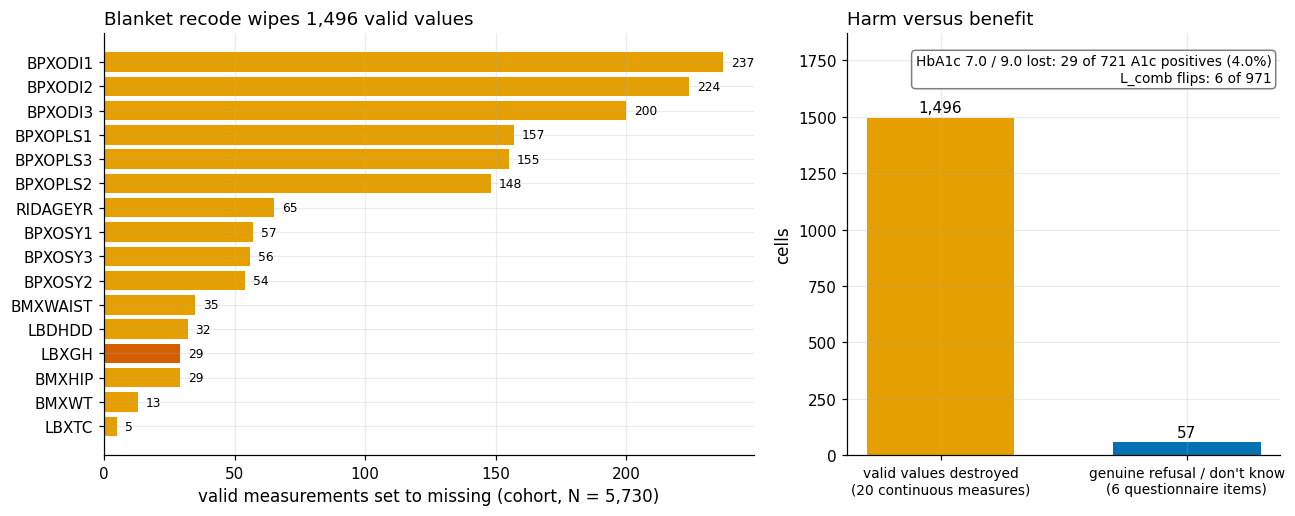

saved figures/S3_blanket_recode_damage.png


In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
d = dmg[dmg["valid_cells_destroyed"] > 0].iloc[::-1]
col = [OI["vermillion"] if v == "LBXGH" else OI["orange"] for v in d["var"]]
a1.barh(d["var"], d["valid_cells_destroyed"], color=col)
for y, n in enumerate(d["valid_cells_destroyed"]):
    a1.text(n + 3, y, str(n), va="center", fontsize=8)
a1.set_xlabel("valid measurements set to missing (cohort, N = 5,730)")
a1.set_title(f"Blanket recode wipes {n_destroyed:,} valid values", loc="left")
bars = [("valid values destroyed\n(20 continuous measures)", n_destroyed, OI["orange"]),
        ("genuine refusal / don't know\n(6 questionnaire items)", n_q, OI["blue"])]
a2.bar([b[0] for b in bars], [b[1] for b in bars], color=[b[2] for b in bars], width=0.6)
for x, b in enumerate(bars):
    a2.text(x, b[1] + 25, f"{b[1]:,}", ha="center", fontsize=10)
a2.set_ylabel("cells"); a2.set_ylim(0, n_destroyed * 1.25); a2.tick_params(axis="x", labelsize=9)
a2.set_title("Harm versus benefit", loc="left")
a2.text(0.98, 0.95, f"HbA1c 7.0 / 9.0 lost: {lost_pos} of {int(a1c_pos.sum())} A1c positives ({lost_pos / a1c_pos.sum():.1%})\n"
        f"L_comb flips: {flips} of {int(l_comb.sum())}", transform=a2.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=OI["grey"]))
fig.tight_layout()
f_blank = plots.savefig(fig, "S3_blanket_recode_damage",
                        caption=f"Left: valid measurements removed by a blanket recode of 7/9/77/99/777/999/7777/9999 in the cohort, by variable "
                                f"({n_destroyed:,} in total; HbA1c in red). Right: the shortcut destroys {n_destroyed:,} valid values to clean {n_q} genuine "
                                f"refusal/don't-know answers in the questionnaire items; it removes {lost_pos}/{int(a1c_pos.sum())} HbA1c-defined positives, "
                                f"of which {flips} of {int(l_comb.sum())} L_comb positives flip.")
plt.show(); print("saved", f_blank)

**So what (non-obvious finding of the profiling).** On the same 5,730 adults the blanket recode destroys **1,496 valid measurements** (mostly diastolic pressure and pulse, where 77 and 99 are ordinary readings; 2,472 in the whole release). The harm reaches the label: all 29 HbA1c values it removes are 7.0 % (28) or 9.0 % (1), i.e. **29 of 721 HbA1c-defined positives (4.0 %)**. Under `L_comb` only **6 of 971** positives flip, because the other 23 also report a diagnosis: self-report hides the error. Applied to every numeric column it also erases real categories (the 363 multiracial adults, `RIDRETH3 = 7`). Its benefit is **57** genuine codes, so harm exceeds gain about 26-fold. **Decision (DR-S3-02):** the per-variable map is the systematic arm; the blanket recode survives only as the naive M0 arm (§6.9).

In [13]:
M3["blanket_recode"] = {
    "valid_cells_destroyed_cohort": n_destroyed, "valid_cells_destroyed_full_file_same_20_vars": n_destroyed_full,
    "candidates": list(io.CONTINUOUS_CANDIDATES),
    "per_variable": dict(zip(dmg["var"], dmg["valid_cells_destroyed"].astype(int))),
    "a1c_positives_lost": lost_pos, "a1c_positives": int(a1c_pos.sum()), "a1c_lost_share": lost_pos / int(a1c_pos.sum()),
    "l_comb_flips": flips, "l_comb_positives": int(l_comb.sum()),
    "questionnaire_only_cells": n_q, "questionnaire_only_per_item": q_arm.to_dict(),
    "all_numeric_recoded": n_blank_all, "all_numeric_genuine": n_blank_genuine,
    "ridreth3_7_destroyed": int(aud_blank.set_index("var").loc["RIDRETH3", "valid_destroyed"]),
}

## 5 Consistency checks

**Why.** Internal consistency tests the data against facts that must hold: BMI is weight / height², systolic pressure exceeds diastolic, and pulse pressure and waist-to-height ratio stay within plausible bounds. Questions asked only of a sub-group (skip patterns) define who *can* have a value. That matters for leakage: a variable asked only of diagnosed people is a disguised label.

In [14]:
bmx = io.load_file("BMX_L")[0]
v = bmx.dropna(subset=["BMXWT", "BMXHT", "BMXBMI"])
bmi_diff = (v["BMXWT"] / (v["BMXHT"] / 100) ** 2 - v["BMXBMI"]).abs()
bpx = io.load_file("BPXO_L")[0]
chk = [["BMI = weight / height^2: valid triples (BMX_L)", len(v), "max |diff| = %.3f; > 0.1: %d" % (bmi_diff.max(), (bmi_diff > 0.1).sum())]]
pp_rows = []
for src_name, df in [("BPXO_L file", bpx), ("cohort", coh)]:
    for i in (1, 2, 3):
        s, dd = df[f"BPXOSY{i}"], df[f"BPXODI{i}"]
        pp = s - dd
        pp_rows.append({"population": src_name, "reading": i, "valid": int((s.notna() & dd.notna()).sum()),
                        "SBP <= DBP": int((s <= dd).sum()), "pulse pressure < 20": int((pp < 20).sum()),
                        "pulse pressure > 100": int((pp > 100).sum())})
pp_tab = pd.DataFrame(pp_rows)
whtr_gt1 = int((coh["whtr"] > 1).sum())
chk.append(["Waist-to-height ratio > 1 (cohort)", int(coh["whtr"].notna().sum()), f"{whtr_gt1} flagged"])
chk = pd.DataFrame(chk, columns=["check", "n", "result"])
display(chk); display(pp_tab)

diq_raw = io.read_xpt("DIQ_L")
univ = []
for var in ("DIQ050", "DIQ070"):
    ans = diq_raw[var].notna()
    g = diq_raw.loc[ans]
    univ.append({"var": var, "answered": int(ans.sum()),
                 "DIQ010=1": int((g["DIQ010"] == 1).sum()), "DIQ010=3": int((g["DIQ010"] == 3).sum()),
                 "DIQ010=2 & DIQ160=1": int(((g["DIQ010"] == 2) & (g["DIQ160"] == 1)).sum()),
                 "other": int((~((g["DIQ010"].isin([1, 3])) | ((g["DIQ010"] == 2) & (g["DIQ160"] == 1)))).sum())})
univ = pd.DataFrame(univ)
display(univ)
coh_dia = coh[coh["DIQ070"] == 1]
d070 = {"self-reported diabetes": int((coh_dia["DIQ010"] == 1).sum()), "borderline": int((coh_dia["DIQ010"] == 3).sum()),
        "no diabetes (told prediabetes)": int((coh_dia["DIQ010"] == 2).sum())}
print("cohort, DIQ070 = 1 (takes oral glucose-lowering medication):", d070)
consistency = pd.concat([chk.assign(kind="arithmetic"), pp_tab.assign(kind="blood pressure")], ignore_index=True)
consistency.to_csv(OUT / "consistency_checks.csv", index=False, lineterminator="\n")

assert len(v) == 8471 and bmi_diff.max() <= 0.05 + 1e-9 and (bmi_diff > 0.1).sum() == 0
assert pp_tab["SBP <= DBP"].sum() == 0 and whtr_gt1 == 4
assert univ.loc[0, ["answered", "DIQ010=1", "other"]].tolist() == [1081, 1081, 0]
assert univ.loc[1, ["DIQ010=1", "DIQ010=3", "DIQ010=2 & DIQ160=1", "other"]].tolist() == [1081, 282, 918, 0]

,check,n,result
0,BMI = weight / height^2: valid triples (BMX_L),8471,max |diff| = 0.050; > 0.1: 0
1,Waist-to-height ratio > 1 (cohort),5462,4 flagged


,population,reading,valid,SBP <= DBP,pulse pressure < 20,pulse pressure > 100
0,BPXO_L file,1,7517,0,12,37
1,BPXO_L file,2,7505,0,8,43
2,BPXO_L file,3,7480,0,11,32
3,cohort,1,5550,0,5,34
4,cohort,2,5544,0,2,39
5,cohort,3,5531,0,3,29


,var,answered,DIQ010=1,DIQ010=3,DIQ010=2 & DIQ160=1,other
0,DIQ050,1081,1081,0,0,0
1,DIQ070,2281,1081,282,918,0


cohort, DIQ070 = 1 (takes oral glucose-lowering medication): {'self-reported diabetes': 592, 'borderline': 44, 'no diabetes (told prediabetes)': 41}


**So what.** The arithmetic holds: BMI recomputes for all 8,471 valid triples (largest difference 0.050), no reading has systolic ≤ diastolic, and implausible pulse pressures and four waist-to-height ratios above 1 are flagged. The skip patterns matter more: `DIQ050` (insulin) is answered only by the 1,081 people reporting diabetes, and `DIQ070` (pills) also by borderline and prediabetic respondents (41 non-diabetic and 44 borderline cohort adults take them). **Decision (DR-S3-06):** both are inadmissible; the treatment-aware label (§5.8) uses them only inside this universe.

In [15]:
M3["consistency"] = {"bmi_triples": len(v), "bmi_max_abs_diff": float(bmi_diff.max()), "bmi_diff_gt_0_1": int((bmi_diff > 0.1).sum()),
                     "sbp_le_dbp": int(pp_tab["SBP <= DBP"].sum()),
                     "pp_lt20_cohort": pp_tab.query("population == 'cohort'")["pulse pressure < 20"].tolist(),
                     "pp_gt100_cohort": pp_tab.query("population == 'cohort'")["pulse pressure > 100"].tolist(),
                     "pp_lt20_file": pp_tab.query("population == 'BPXO_L file'")["pulse pressure < 20"].tolist(),
                     "pp_gt100_file": pp_tab.query("population == 'BPXO_L file'")["pulse pressure > 100"].tolist(),
                     "whtr_gt1": whtr_gt1, "diq050_universe": univ.iloc[0].drop("var").to_dict(),
                     "diq070_universe": univ.iloc[1].drop("var").to_dict(), "cohort_diq070_yes": d070}

## 6 Top-coding

**Why.** Disclosure control caps age at 80 and the income-to-poverty ratio at 5. A capped value is a bound rather than a measurement. A model that treats "80" as exactly 80 years, or that loses the 12.8 % of people with no income ratio, misreads the data. Two questions decide the treatment: how many people sit at each cap, and whether the cap hides a change in risk.

In [16]:
coh["L_comb"] = l_comb.astype(int)
age_top, pir_top, pir_miss = int(coh["age_top"].sum()), int(coh["pir_top"].sum()), int(coh["pir_miss"].sum())
prev_80 = coh.loc[coh["RIDAGEYR"] == 80, "L_comb"].mean()
prev_7079 = coh.loc[coh["RIDAGEYR"].between(70, 79), "L_comb"].mean()
top = pd.DataFrame([
    ["age_top (RIDAGEYR = 80)", age_top, age_top / len(coh)],
    ["pir_top (INDFMPIR = 5)", pir_top, pir_top / len(coh)],
    ["pir_miss (INDFMPIR missing)", pir_miss, pir_miss / len(coh)],
], columns=["flag", "n", "share"])
display(top)
print(f"L_comb prevalence (unweighted): age 80 group {prev_80:.1%}, ages 70-79 {prev_7079:.1%}")
assert (age_top, pir_top, pir_miss) == (321, 1282, 734)
assert close(prev_80, 0.262, 0.001) and close(prev_7079, 0.254, 0.001)

,flag,n,share
0,age_top (RIDAGEYR = 80),321,0.056021
1,pir_top (INDFMPIR = 5),1282,0.223735
2,pir_miss (INDFMPIR missing),734,0.128098


L_comb prevalence (unweighted): age 80 group 26.2%, ages 70-79 25.4%


**So what.** 321 adults (5.6 %) are capped at age 80 and 1,282 (22.4 %) at an income ratio of 5; another 734 (12.8 %) have no income ratio. The age cap hides little: unweighted `L_comb` prevalence is 26.2 % at the cap against 25.4 % at ages 70–79. **Decision (DR-S3-05):** keep the values and carry the flags `age_top`, `pir_top` and `pir_miss`; whether they help a model is tested as block B4 (§6.6).

In [17]:
M3["top_coding"] = {"age_top": age_top, "pir_top": pir_top, "pir_top_share": pir_top / len(coh),
                    "pir_miss": pir_miss, "pir_miss_share": pir_miss / len(coh),
                    "prev_age80": float(prev_80), "prev_age70_79": float(prev_7079)}

## 7 Missing-data mechanism for HbA1c

**Why.** The cohort keeps only examined adults *with* HbA1c; if missingness depended on diabetes itself, no weighting could repair the label. MCAR can be rejected from observed covariates, MAR vs MNAR cannot be tested. An unweighted logistic model for missingness among the 6,064 examined adults shows who is missing (Little's test is not used: it assumes normality and can only reject MCAR).

In [18]:
mrg = io.load_merged(sentinels="per_variable")
ex = mrg[(mrg["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (mrg["RIDSTATR"] == 2)].copy()
y_miss = ex["LBXGH"].isna().astype(int)
race_ex = ex["RIDRETH3"].map(io.RACE_LABELS)
Xm = pd.DataFrame({"age (per 10 y)": ex["RIDAGEYR"] / 10, "female": (ex["RIAGENDR"] == 2).astype(int)}, index=ex.index)
for r in ["NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"]:
    Xm[r] = (race_ex == r).astype(int)
Xm["PIR (per unit)"] = ex["INDFMPIR"].fillna(ex["INDFMPIR"].mean())
Xm["PIR missing"] = ex["INDFMPIR"].isna().astype(int)
Xm["BMI (per unit)"] = ex["BMXBMI"].fillna(ex["BMXBMI"].mean())
Xm["BMI missing"] = ex["BMXBMI"].isna().astype(int)
Xm["uninsured"] = (ex["HIQ011"] == 2).astype(int)
Xm["no usual place of care"] = (ex["HUQ030"] == 2).astype(int)
Xm["self-reported diabetes"] = (ex["DIQ010"] == 1).astype(int)
Xm["told hypertension"] = (ex["BPQ020"] == 1).astype(int)
fit = sm.Logit(y_miss, sm.add_constant(Xm)).fit(disp=0)
ci = fit.conf_int()
or_tab = pd.DataFrame({"OR": np.exp(fit.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]), "p": fit.pvalues}).drop("const")
auc_miss = roc_auc_score(y_miss, fit.predict())
miss_rate = ex.assign(m=y_miss, race=race_ex).groupby("race")["m"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "missing_share"})
print(f"examined adults {len(ex):,}; HbA1c missing {int(y_miss.sum())} ({y_miss.mean():.1%}); LLR p = {fit.llr_pvalue:.1e}; AUC = {auc_miss:.3f}")
display(or_tab.round(3)); display(miss_rate.round(3))
or_tab.to_csv(OUT / "missingness_or.csv", lineterminator="\n")

assert len(ex) == 6064 and int(y_miss.sum()) == 297
assert fit.llr_pvalue < 1e-10 and close(auc_miss, 0.65, 0.005)
assert close(or_tab.loc["NH Black", "OR"], 1.85, 0.01) and close(or_tab.loc["NH Black", "ci_low"], 1.35, 0.01) and close(or_tab.loc["NH Black", "ci_high"], 2.54, 0.01)
assert close(or_tab.loc["PIR (per unit)", "OR"], 0.82, 0.01) and close(or_tab.loc["age (per 10 y)", "OR"], 0.89, 0.01)
assert close(or_tab.loc["BMI missing", "OR"], 2.6, 0.06) and close(or_tab.loc["self-reported diabetes", "OR"], 1.15, 0.01)

examined adults 6,064; HbA1c missing 297 (4.9%); LLR p = 2.8e-11; AUC = 0.650


,OR,ci_low,ci_high,p
age (per 10 y),0.893,0.826,0.965,0.004
female,0.948,0.745,1.205,0.660
NH Black,1.853,1.351,2.541,0.000
NH Asian,1.383,0.846,2.263,0.196
Mexican American,0.772,0.448,1.328,0.349
Other Hispanic,0.842,0.541,1.309,0.444
Other/Multi,1.244,0.785,1.973,0.353
PIR (per unit),0.820,0.753,0.892,0.000
PIR missing,1.572,1.151,2.148,0.004
BMI (per unit),0.997,0.981,1.014,0.723


,n,missing_share
race,,
Mexican American,405,0.040
NH Asian,335,0.060
NH Black,753,0.093
NH White,3569,0.040
Other Hispanic,614,0.042
Other/Multi,388,0.059


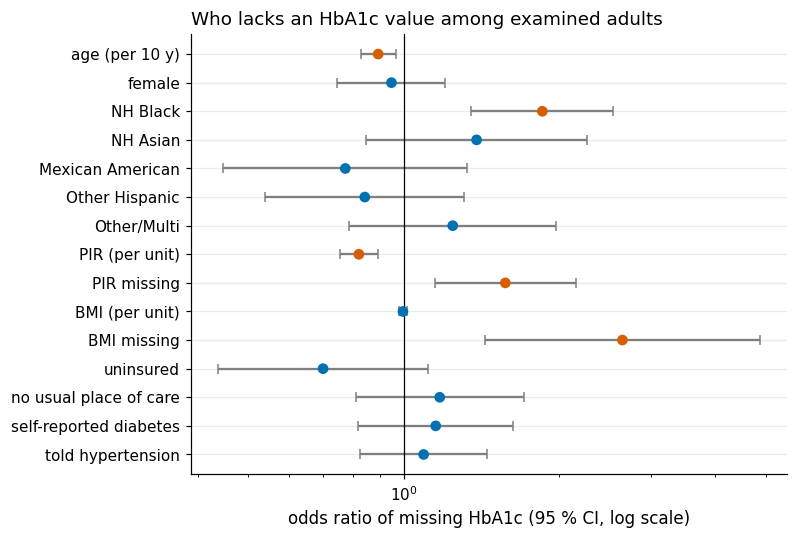

saved figures/S3_missing_hba1c_or.png


In [19]:
ot = or_tab.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.2))
sig = (ot["ci_low"] > 1) | (ot["ci_high"] < 1)
ax.errorbar(ot["OR"], range(len(ot)), xerr=[ot["OR"] - ot["ci_low"], ot["ci_high"] - ot["OR"]], fmt="none", ecolor=OI["grey"], capsize=3)
ax.scatter(ot["OR"], range(len(ot)), color=[OI["vermillion"] if s else OI["blue"] for s in sig], zorder=3)
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log"); ax.set_yticks(range(len(ot)), ot.index)
ax.set_xlabel("odds ratio of missing HbA1c (95 % CI, log scale)")
ax.set_title("Who lacks an HbA1c value among examined adults", loc="left")
f_miss = plots.savefig(fig, "S3_missing_hba1c_or",
                       caption=f"Unweighted logistic model for missing HbA1c among {len(ex):,} examined adults ({int(y_miss.sum())} missing). "
                               f"Odds ratios with 95 % Wald CIs; red = CI excludes 1. LLR p = {fit.llr_pvalue:.1e}, AUC = {auc_miss:.2f}. Reference: NH White.")
plt.show(); print("saved", f_miss)

**So what.** 297 of 6,064 examined adults (4.9 %; all examined adults, pregnant women included – §9.7 uses the 6,023 non-pregnant ones, 293 missing) lack HbA1c, and missingness clearly depends on observed covariates (likelihood-ratio p = 2.8 × 10⁻¹¹, AUC 0.65). Data are **not MCAR**. Associations with missing HbA1c:

| Covariate | OR (95 % CI) |
|---|---|
| Non-Hispanic Black | 1.85 (1.35, 2.54) |
| Income ratio, per unit | 0.82 |
| Age, per 10 years | 0.89 |
| Missing BMI | 2.6 (typically an incomplete examination) |
| Self-reported diabetes | 1.15 (0.82, 1.63) |

Self-reported diabetes, the closest observable stand-in for the outcome, shows no association.

The correct wording is narrow: **given these covariates there is no evidence against MAR, and MNAR cannot be tested with these data.** **Decision (DR-S3-04):** this wording is used everywhere; WTPH2YR already contains the NCHS blood-sample non-response adjustment, and an inverse-probability-weighting / delta-adjustment sensitivity analysis follows in §9.7.

In [20]:
M3["missingness"] = {"examined_adults": len(ex), "a1c_missing": int(y_miss.sum()), "a1c_missing_share": float(y_miss.mean()),
                     "llr_p": float(fit.llr_pvalue), "auc": float(auc_miss),
                     "odds_ratios": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in or_tab.iterrows()},
                     "missing_share_by_race": miss_rate["missing_share"].to_dict(),
                     "wording": "not MCAR; no evidence against MAR given covariates; MNAR untestable (sensitivity in §9.7)"}

## 8 Outliers: a three-layer rule

**Why.** In clinical data the extremes are often the signal (a very high HbA1c *is* diabetes), so deleting beyond 1.5 × IQR removes cases, not errors. Three layers: hard physiological limits and a robust z-score (|z| > 3.5) only flag; a human reviews what both flag. The harm of blind deletion is measured directly.

In [21]:
LIMITS = {"BMXBMI": (12, 70), "bp_sys_mean": (70, 260), "bp_dia_mean": (30, 150), "LBXTC": (60, 500), "LBDHDD": (10, 200), "LBXGH": (3, 18)}
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad
out_rows = []
for var, (lo, hi) in LIMITS.items():
    s = coh[var]
    hard = (s < lo) | (s > hi)
    rz = robust_z(s).abs() > 3.5
    out_rows.append({"var": var, "valid": int(s.notna().sum()), "min": s.min(), "max": s.max(), "limits": f"{lo}-{hi}",
                     "layer1_outside_limits": int(hard.sum()), "layer2_robust_z_gt_3.5": int(rz.sum()),
                     "both_layers": int((hard & rz).sum())})
outl = pd.DataFrame(out_rows)
display(outl)
outl.to_csv(OUT / "outlier_flags.csv", index=False, lineterminator="\n")
review = int(outl["both_layers"].sum())
print(f"layer 3 (manual review queue): {review} values flagged by both layers")

# Layer 3: the value(s) flagged by both layers, with the measurements needed to judge them.
both = pd.concat([coh.loc[((coh[v] < lo) | (coh[v] > hi)) & (robust_z(coh[v]).abs() > 3.5)].assign(var=v, value=lambda d, v=v: d[v])
                  for v, (lo, hi) in LIMITS.items()])
both["bmi_recomputed"] = (both["BMXWT"] / (both["BMXHT"] / 100) ** 2).round(1)
display(both[["var", "value", "BMXWT", "BMXHT", "bmi_recomputed", "RIDAGEYR"]]
        .rename(columns={"BMXWT": "weight_kg", "BMXHT": "height_cm", "RIDAGEYR": "age"}).reset_index(drop=True))
assert len(both) == review == 1 and both["var"].iloc[0] == "BMXBMI"
assert abs(both["bmi_recomputed"].iloc[0] - both["value"].iloc[0]) <= 0.1
REVIEW_OUTCOME = (f"BMI {both['value'].iloc[0]:.1f} (weight {both['BMXWT'].iloc[0]:.1f} kg, height {both['BMXHT'].iloc[0]:.1f} cm) "
                  "recomputes from the measured weight and height: plausible class III obesity, kept with its flag")
print("layer-3 decision:", REVIEW_OUTCOME)

def iqr_fence(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i), q1 - 1.5 * i, q3 + 1.5 * i

a1c = coh["LBXGH"]
fl, lo_f, hi_f = iqr_fence(a1c)
n_fl, n_fl_pos = int(fl.sum()), int((fl & (a1c >= C.HBA1C_DIABETES)).sum())
JOINT = ["BMXBMI", "BMXWAIST", "BPXOSY1", "LBXTC", "LBDHDD"]
joint = np.zeros(len(coh), bool)
for c_ in JOINT:
    joint |= iqr_fence(coh[c_])[0].to_numpy()
la1c = (a1c >= C.HBA1C_DIABETES)
prev_del, prev_keep = la1c[joint].mean(), la1c[~joint].mean()
print(f"HbA1c 1.5xIQR fence: [{lo_f:.2f}, {hi_f:.2f}] flags {n_fl} rows, {n_fl_pos} of them A1c >= 6.5 ({n_fl_pos / la1c.sum():.0%} of {int(la1c.sum())} positives)")
print(f"joint fence on {JOINT}: deletes {int(joint.sum())} rows ({joint.mean():.1%}); A1c-positive share deleted {prev_del:.1%} vs kept {prev_keep:.1%}")
assert close(hi_f, 6.8, 1e-9) and n_fl == 542 and n_fl_pos == 519
assert outl.set_index("var").loc["BMXBMI", "layer1_outside_limits"] == 2 and outl.set_index("var").loc["LBXGH", "layer2_robust_z_gt_3.5"] == 462 and review == 1
assert int(joint.sum()) == 512 and close(prev_del, 0.172, 0.001) and close(prev_keep, 0.121, 0.001)

,var,valid,min,max,limits,layer1_outside_limits,layer2_robust_z_gt_3.5,both_layers
0,BMXBMI,5649,11.1,74.800000,12-70,2,88,1
1,bp_sys_mean,5550,70.0,232.333333,70-260,0,67,0
2,bp_dia_mean,5550,34.0,139.000000,30-150,0,29,0
3,LBXTC,5459,62.0,438.000000,60-500,0,21,0
4,LBDHDD,5459,22.0,159.000000,10-200,0,60,0
5,LBXGH,5730,3.2,17.100000,3-18,0,462,0


layer 3 (manual review queue): 1 values flagged by both layers


,var,value,weight_kg,height_cm,bmi_recomputed,age
0,BMXBMI,74.8,185.2,157.3,74.8,41.0


layer-3 decision: BMI 74.8 (weight 185.2 kg, height 157.3 cm) recomputes from the measured weight and height: plausible class III obesity, kept with its flag
HbA1c 1.5xIQR fence: [4.40, 6.80] flags 542 rows, 519 of them A1c >= 6.5 (72% of 721 positives)
joint fence on ['BMXBMI', 'BMXWAIST', 'BPXOSY1', 'LBXTC', 'LBDHDD']: deletes 512 rows (8.9%); A1c-positive share deleted 17.2% vs kept 12.1%


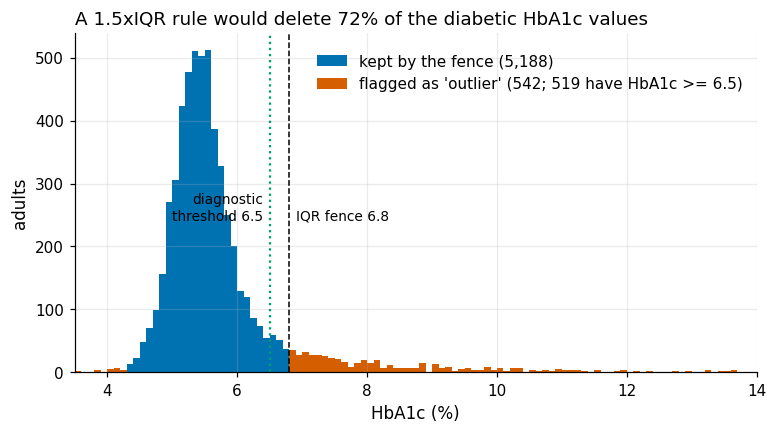

saved figures/S3_iqr_fence_harm.png


In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(3.0, 17.6, 0.1)
ax.hist(a1c[~fl], bins=bins, color=OI["blue"], label=f"kept by the fence ({len(coh) - n_fl:,})")
ax.hist(a1c[fl], bins=bins, color=OI["vermillion"], label=f"flagged as 'outlier' ({n_fl}; {n_fl_pos} have HbA1c >= 6.5)")
ytop = ax.get_ylim()[1]
ax.axvline(hi_f, color="black", ls="--", lw=1); ax.text(hi_f + 0.1, ytop * 0.45, f"IQR fence {hi_f:.1f}", fontsize=9)
ax.axvline(C.HBA1C_DIABETES, color=OI["green"], ls=":", lw=1.5); ax.text(C.HBA1C_DIABETES - 0.1, ytop * 0.45, "diagnostic\nthreshold 6.5", ha="right", fontsize=9)
ax.set_xlim(3.5, 14); ax.set_xlabel("HbA1c (%)"); ax.set_ylabel("adults")
ax.set_title(f"A 1.5xIQR rule would delete {n_fl_pos / la1c.sum():.0%} of the diabetic HbA1c values", loc="left")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.98))
f_iqr = plots.savefig(fig, "S3_iqr_fence_harm",
                      caption=f"HbA1c distribution in the cohort (N = {len(coh):,}). A 1.5xIQR fence (upper bound {hi_f:.1f} %) flags {n_fl} values; "
                              f"{n_fl_pos} of them are at or above the diagnostic threshold of 6.5 %, i.e. {n_fl_pos / la1c.sum():.0%} of the {int(la1c.sum())} HbA1c-defined cases.")
plt.show(); print("saved", f_iqr)

**So what.** The hard limits flag 2 BMI values and the robust z-score 462 HbA1c values (the diabetic tail). The one value flagged by both, a BMI of 74.8, recomputes from measured weight (185.2 kg) and height (157.3 cm) and is kept. Blind deletion would be costly: the HbA1c 1.5 × IQR fence (6.8 %) flags 542 rows, 519 of them with HbA1c ≥ 6.5 % (**72 % of all HbA1c-defined cases**); a joint fence over five predictors deletes 512 rows with a higher positive share (17.2 % vs 12.1 %). **Decision (DR-S3-03):** keep every value; skewness is handled in block B5 (§6.7).

In [23]:
M3["outliers"] = {"layer_table": outl.set_index("var")[["layer1_outside_limits", "layer2_robust_z_gt_3.5", "both_layers"]].to_dict("index"),
                  "manual_review": review, "manual_review_outcome": REVIEW_OUTCOME,
                  "a1c_iqr_fence_upper": float(hi_f), "a1c_iqr_flagged": n_fl, "a1c_iqr_flagged_positive": n_fl_pos,
                  "a1c_iqr_positive_share": n_fl_pos / int(la1c.sum()),
                  "joint_fence_vars": JOINT, "joint_fence_deleted": int(joint.sum()), "joint_fence_share": float(joint.mean()),
                  "joint_fence_prev_deleted": float(prev_del), "joint_fence_prev_kept": float(prev_keep)}

## 9 Data-quality dimension matrix

**Why.** The checks above must add up to a judgement per quality dimension. The matrix uses the six DAMA UK (2013) dimensions (completeness, uniqueness, timeliness, validity, accuracy, consistency) and adds **credibility** from ISO/IEC 25012 (2008) for what the files cannot show internally: low response rates and a self-reported label. Each dimension gets a metric, a threshold, the computed result and a verdict.

In [24]:
feat = inc[(inc["admissible"].isin(["T1", "T2"]))]["var"].tolist()
miss_by_var = coh[feat].isna().mean().sort_values(ascending=False)
structural = {"PAD800": "skip: only if moderate activity > 0", "PAD820": "skip: only if vigorous activity > 0",
              "PAD790U": "skip: unit only if frequency > 0", "PAD810U": "skip: unit only if frequency > 0"}
mv = miss_by_var.rename("missing_share").to_frame()
mv["structural_skip"] = mv.index.map(structural).fillna("")
mv.to_csv(OUT / "missingness_by_var.csv", lineterminator="\n")
item_miss = mv[mv["structural_skip"] == ""]["missing_share"]
print("highest feature missingness (cohort):"); display(mv.head(8).round(3))

# validity: values outside the codebook range after per-variable recoding (top codes and special codes allowed)
cbs = io.spec_from_codebooks().set_index(["file", "var"])
viol = 0; checked = 0
for _, r in inc[(inc["dtype"] == "continuous")].iterrows():
    s = mrg[r["var"]].dropna()
    ref = cbs.loc[(r["file"], r["var"])]
    allowed = set(io._codes(ref["top_code"])) | {io._num(p.split("=")[0]) for p in ref["special_codes"].split("; ") if "=" in p}
    bad = ~(s.between(r["valid_min"], r["valid_max"]) | s.isin(allowed))
    viol += int(bad.sum()); checked += len(s)
print(f"validity: {checked:,} continuous values checked against codebook ranges; outside range: {viol}")
assert viol == 0

resp_int, resp_mec = 0.346, 0.257   # NCHS cycle overview (not computable from the files)
dq = pd.DataFrame([
    ["Completeness", "max item missingness among T1/T2 features in cohort (excl. structural skips)", "<= 40 % (scope-revision trigger)",
     f"{item_miss.max():.1%} ({item_miss.idxmax()}); HbA1c missing in 4.9 % of examined adults, not MCAR", "pass with flags"],
    ["Uniqueness", "duplicate SEQN per file; files subset of DEMO_L", "0 duplicates",
     f"{int((~uniq['seqn_unique']).sum())} duplicates in 16 files; all subsets", "pass"],
    ["Timeliness", "collection window; drift test", "single documented cycle",
     "Aug 2021 - Aug 2023, one cycle; no drift test possible (no pooling)", "not assessable"],
    ["Validity", "values outside codebook range after per-variable recode; sentinel codes traceable", "0 out of range; 100 % traceable",
     f"{viol} of {checked:,} values out of range; {int(sent['traceable'].sum())}/{len(sent)} sentinel variables traceable; XPT artefact repaired ({n_art:,} cells)", "pass"],
    ["Accuracy", "BMI recomputation; external anchor; label agreement", "|diff| <= 0.1; NCHS Data Brief 516 replication within 0.1 pp (§4.3)",
     f"max BMI diff {bmi_diff.max():.3f}; label accuracy limited: self-report vs HbA1c disagree (§5.1 kappa)", "pass for measures, limited for label"],
    ["Consistency", "SBP > DBP; skip-pattern universes; duplicate weight columns identical", "0 violations",
     f"SBP <= DBP: {int(pp_tab['SBP <= DBP'].sum())}; WHtR > 1: {whtr_gt1} flagged; DIQ050/DIQ070 universes as documented", "pass"],
    ["Credibility (ISO/IEC 25012)", "response rates; label source", "documented, not correctable",
     f"interview response {resp_int:.1%}, examination {resp_mec:.1%}; self-reported diagnosis part of the label", "limited"],
], columns=["dimension", "metric", "threshold", "result", "verdict"])
display(dq)
dq.to_csv(OUT / "quality_matrix.csv", index=False, lineterminator="\n")

highest feature missingness (cohort):


,missing_share,structural_skip
PAD820,0.557,skip: only if vigorous activity > 0
PAD810U,0.556,skip: unit only if frequency > 0
PAD800,0.209,skip: only if moderate activity > 0
PAD790U,0.207,skip: unit only if frequency > 0
INDFMPIR,0.128,
BMXHIP,0.054,
LBXTC,0.047,
LBDHDD,0.047,


validity: 214,422 continuous values checked against codebook ranges; outside range: 0

,dimension,metric,threshold,result,verdict
0,Completeness,max item missingness among T1/T2 features in cohort (excl. structu...,<= 40 % (scope-revision trigger),"12.8% (INDFMPIR); HbA1c missing in 4.9 % of examined adults, not MCAR",pass with flags
1,Uniqueness,duplicate SEQN per file; files subset of DEMO_L,0 duplicates,0 duplicates in 16 files; all subsets,pass
2,Timeliness,collection window; drift test,single documented cycle,"Aug 2021 - Aug 2023, one cycle; no drift test possible (no pooling)",not assessable
3,Validity,values outside codebook range after per-variable recode; sentinel ...,0 out of range; 100 % traceable,"0 of 214,422 values out of range; 25/25 sentinel variables traceab...",pass
4,Accuracy,BMI recomputation; external anchor; label agreement,|diff| <= 0.1; NCHS Data Brief 516 replication within 0.1 pp (§4.3),max BMI diff 0.050; label accuracy limited: self-report vs HbA1c d...,"pass for measures, limited for label"
5,Consistency,SBP > DBP; skip-pattern universes; duplicate weight columns identical,0 violations,SBP <= DBP: 0; WHtR > 1: 4 flagged; DIQ050/DIQ070 universes as doc...,pass
6,Credibility (ISO/IEC 25012),response rates; label source,"documented, not correctable","interview response 34.6%, examination 25.7%; self-reported diagnos...",limited


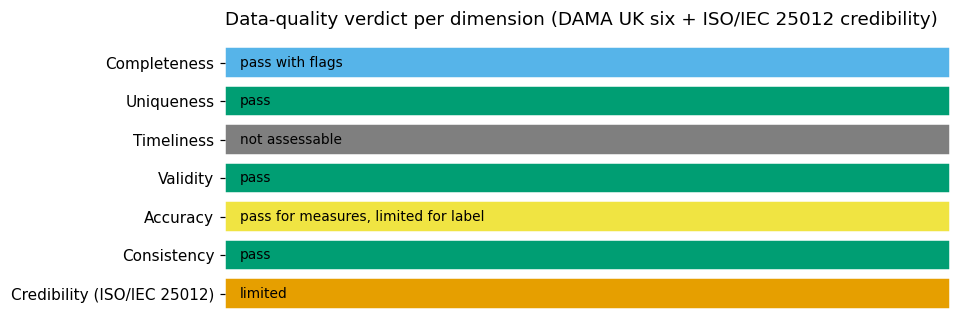

saved figures/S3_quality_matrix.png


In [25]:
order = {"pass": 0, "pass with flags": 1, "pass for measures, limited for label": 2, "limited": 3, "not assessable": 4}
cmap = {0: OI["green"], 1: OI["sky"], 2: OI["yellow"], 3: OI["orange"], 4: OI["grey"]}
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for i, (dim, ver) in enumerate(zip(dq["dimension"], dq["verdict"])):
    ax.barh(i, 1, color=cmap[order[ver]], edgecolor="white")
    ax.text(0.02, i, ver, va="center", fontsize=9)
ax.set_yticks(range(len(dq)), dq["dimension"]); ax.invert_yaxis(); ax.set_xticks([]); ax.grid(False)
ax.set_xlim(0, 1); ax.set_title("Data-quality verdict per dimension (DAMA UK six + ISO/IEC 25012 credibility)", loc="left")
for s_ in ax.spines.values():
    s_.set_visible(False)
f_dq = plots.savefig(fig, "S3_quality_matrix", caption="Verdict per data-quality dimension; metrics, thresholds and results in results/S3/quality_matrix.csv.")
plt.show(); print("saved", f_dq)

**So what.** With the two read-time problems fixed the measurements are trustworthy (unique keys, codebook ranges, BMI recomputes, coherent BP pairs). The weak points are **credibility** (response 34.6 % / 25.7 %, partly self-reported label), **timeliness** (one cycle) and **completeness** with flags (§3.7); no admissible variable meets the scope-revision trigger. **Decision (DR-S3-07):** `scope-freeze`; credibility and label accuracy go to §5 and §10 as limitations.

In [26]:
M3["quality_matrix"] = dq.set_index("dimension")[["result", "verdict"]].to_dict("index")
M3["validity"] = {"continuous_values_checked": checked, "out_of_range": viol}
M3["max_item_missing_feature"] = {"var": item_miss.idxmax(), "share": float(item_miss.max())}

## Outputs

Decisions of §2–§3 with their evidence (`governance/register/S2.csv`, `S3.csv`; every `evidence_value` is filled from a variable computed in this run) and the stored metrics.

In [27]:
reg2 = write_register("S2", [
    dict(dr_id="DR-S2-01", stage="S2", date=TODAY, type="governance", finding="NCHS DUA forbids re-identification, linkage and study of disclosure methods; presentation standards apply to survey estimates",
         evidence_ref="governance/dua_checklist.md", evidence_value="5 obligations mapped; 4 presentation rules (n<30, n_eff<30, CI width>=0.30, df<8)",
         decision="Comply as mapped in the checklist; external validation against published aggregates only; small groups (NH Asian 315) always exploratory",
         alternatives_rejected="External validation by linking other micro-data (forbidden)", status="decided", check_verdict="PASS",
         check_note="Checklist re-read against the DUA page; quasi-identifiers confirmed absent from the loaded columns (minimisation report)"),
    dict(dr_id="DR-S2-02", stage="S2", date=TODAY, type="weights", finding="Each weight belongs to a sub-sample; zero weights mean 'not in sub-sample'",
         evidence_ref="governance/dua_checklist.md, section 3; §3.1",
         evidence_value=f"WTMEC2YR=0: {M3['zero_weights']['WTMEC2YR_0']}; WTPH2YR=0: {M3['zero_weights']['WTPH2YR_0']}; cohort WTPH2YR=0: {zero_in_cohort}",
         decision="WTPH2YR for every cohort analysis with HbA1c or lipids; WTSAF2YR only for DB516/SL5; WTINT2YR/WTMEC2YR for interview/exam-only descriptions; zero weights -> NaN; domains by zero weights, never row deletion",
         alternatives_rejected="WTMEC2YR for HbA1c analyses (ignores blood-sample non-response); unweighted descriptions", status="decided", check_verdict="PASS",
         check_note="Zero-weight counts recomputed; WTMEC2YR=0 equals RIDSTATR=1 (3,073)"),
    dict(dr_id="DR-S2-03", stage="S2", date=TODAY, type="minimisation", finding="16 files contain 175 columns, many not needed for the purpose (child items, quasi-identifiers, duplicates)",
         evidence_ref="results/S2/minimisation_report.csv; results/S2/minimisation_columns.csv",
         evidence_value=f"raw {n_raw}, kept {n_kept}, dropped {n_drop} (each with reason)",
         decision="Loader keeps only spec-included columns; dropped columns listed with reason",
         alternatives_rejected="Load all columns and select later (purpose limitation violated, more disclosure risk)", status="decided", check_verdict="PASS",
         check_note="Report regenerated from the spec in this run; every dropped column has a non-empty reason (assert)"),
    dict(dr_id="DR-S2-04", stage="S2", date=TODAY, type="specification", finding="Sentinel codes differ by variable and continuous measures have none; a single spec avoids drift between code and documentation",
         evidence_ref="config/variable_spec.csv; nhanes_io.verify_spec",
         evidence_value=f"{len(spec)} spec rows; {n_sentinel_vars} included variables with codebook sentinels; verify_spec problems: {len(problems)}",
         decision="variable_spec.csv (15 documented columns) is the single source; sentinel_codes parsed from the CDC codebooks (Refused / Don't know only); roles and admissibility from the S1 availability rule",
         alternatives_rejected="Hand-written sentinel list; global 7/9/77/99 list", status="decided", check_verdict="PASS",
         check_note="verify_spec re-parses all 16 codebooks and the XPT headers in this run: 0 problems"),
    dict(dr_id="DR-S2-05", stage="S2", date=TODAY, type="provenance", finding="Numbers are only reproducible if the raw files are byte-identical to the CDC release",
         evidence_ref="data/nhanes_2021_2023/MANIFEST.sha256; nhanes_io.ensure_raw_data",
         evidence_value=f"{len(integrity['verified'])}/16 hashes verified; funnel {' -> '.join(f'{n:,}' for n in fun['n'])}",
         decision="Verify hashes at the start of every profiling run; datasheet (Gebru) documents composition and preprocessing",
         alternatives_rejected="Trust the download", status="decided", check_verdict="PASS", check_note="Hashes and funnel recomputed in this run"),
    dict(dr_id="DR-S2-06", stage="S2", date=TODAY, type="coding", finding="Borderline diabetes (DIQ010=3) and uncertain pregnancy (RIDEXPRG=3) are legitimate but ambiguous codes",
         evidence_ref="§3.2–§3.3",
         evidence_value=f"DIQ010=3: {int(legit.loc[0, 'cohort'])} in cohort ({int(legit.loc[0, 'file'])} in file); RIDEXPRG=3: {preg3} in cohort",
         decision="Keep both; DIQ010=3 negative in L_self and flagged (S5 sensitivity SL3); RIDEXPRG=3 kept with flag preg_unknown for a sensitivity drop",
         alternatives_rejected="Recode as missing (loses 213 people with elevated risk); drop RIDEXPRG=3", status="decided", check_verdict="PASS",
         check_note="Counts recomputed and asserted (213/284, 21)"),
])
reg3 = write_register("S3", [
    dict(dr_id="DR-S3-01", stage="S3", date=TODAY, type="data_fix", finding="pandas reads stored zeros in XPT files as 5.4e-79; a where()-based repair turns NaN into 0",
         evidence_ref="results/S3/xpt_artefacts.csv; §3.1", evidence_value=f"{n_art:,} cells in {len(files_hit)} files; PAQ NaN {nan_before} kept by mask, {nan_wrong} after where",
         decision="Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_io.fix_xpt); zero weights -> NaN before weighting",
         alternatives_rejected="where(); leave artefact", status="decided", check_verdict="PASS",
         check_note="Residual 0<|x|<1e-10 = 0 in all files and NaN counts unchanged (asserts)"),
    dict(dr_id="DR-S3-02", stage="S3", date=TODAY, type="cleaning", finding="Blanket recode of 7/9/77/99/777/999/7777/9999 destroys valid measurements; codebook sentinels only exist for questionnaire items",
         evidence_ref="results/S3/sentinel_audit.csv; results/S3/blanket_damage.csv; figures/S3_blanket_recode_damage.png",
         evidence_value=f"{n_destroyed:,} valid cells destroyed (cohort, 20 continuous vars; full file {n_destroyed_full:,}); A1c positives lost {lost_pos}/{int(a1c_pos.sum())}; L_comb flips {flips}/{int(l_comb.sum())}; questionnaire-only arm {n_q} cells",
         decision="Per-variable sentinel recoding from the codebook (systematic arm); blanket recode only as the naive M0 arm in S6",
         alternatives_rejected="Blanket recode; questionnaire-only blanket (cleans 57 cells, needs the same per-variable knowledge)", status="decided", check_verdict="PASS",
         check_note="1,496 / 29 of 721 / 6 of 971 / 57 recomputed and asserted; every recoded code traceable to codebook counts"),
    dict(dr_id="DR-S3-03", stage="S3", date=TODAY, type="outliers", finding="Extreme HbA1c values are the outcome, not errors",
         evidence_ref="results/S3/outlier_flags.csv; figures/S3_iqr_fence_harm.png",
         evidence_value=f"A1c IQR fence {hi_f:.1f}: {n_fl} flagged, {n_fl_pos} with A1c>=6.5 ({n_fl_pos / la1c.sum():.0%} of positives); joint fence deletes {int(joint.sum())} rows, A1c+ share {prev_del:.1%} vs {prev_keep:.1%}",
         decision="Keep all values; three-layer rule (hard limits flag, robust z flag, manual review); transformation/winsorising only as S6 ablation (B5)",
         alternatives_rejected="1.5xIQR deletion; z-score deletion", status="decided", check_verdict="PASS",
         check_note=f"542/519 and 512 recomputed and asserted; layer-3 review of {review} value: {REVIEW_OUTCOME}"),
    dict(dr_id="DR-S3-04", stage="S3", date=TODAY, type="missingness", finding="HbA1c missingness depends on race, income, age and examination completeness, not on self-reported diabetes",
         evidence_ref="results/S3/missingness_or.csv; figures/S3_missing_hba1c_or.png",
         evidence_value=f"{int(y_miss.sum())}/{len(ex)} missing; LLR p={fit.llr_pvalue:.1e}; AUC {auc_miss:.2f}; NH Black OR {or_tab.loc['NH Black', 'OR']:.2f} ({or_tab.loc['NH Black', 'ci_low']:.2f}, {or_tab.loc['NH Black', 'ci_high']:.2f}); self-report OR {or_tab.loc['self-reported diabetes', 'OR']:.2f}",
         decision="Wording: not MCAR; no evidence against MAR given covariates; MNAR untestable. Complete-case cohort with WTPH2YR (includes blood non-response adjustment); MNAR sensitivity (delta / IPW) in S9",
         alternatives_rejected="Little's MCAR test (normality, only rejects MCAR); multiple imputation of the label", status="decided", check_verdict="PASS",
         check_note="Logit refitted in this run; ORs asserted against the reference values", loop_ref="§9.7 MNAR sensitivity"),
    dict(dr_id="DR-S3-05", stage="S3", date=TODAY, type="top_coding", finding="Age capped at 80 and PIR at 5; PIR also missing",
         evidence_ref="§3.6", evidence_value=f"age_top {age_top}; pir_top {pir_top} ({pir_top / len(coh):.1%}); pir_miss {pir_miss} ({pir_miss / len(coh):.1%}); L_comb 80: {prev_80:.1%} vs 70-79: {prev_7079:.1%}",
         decision="Keep values and carry flags age_top, pir_top, pir_miss; their model value tested in S6 block B4 (P06/P07)",
         alternatives_rejected="Treat caps as exact; drop PIR-missing rows (12.8 %)", status="decided", check_verdict="PASS", check_note="Counts and prevalences recomputed and asserted"),
    dict(dr_id="DR-S3-06", stage="S3", date=TODAY, type="leakage", finding="DIQ050 is asked only of diagnosed people; DIQ070 also of borderline and prediabetic respondents",
         evidence_ref="§3.5", evidence_value=f"DIQ050 universe {univ.loc[0, 'answered']} (all DIQ010=1); DIQ070: 1,081 / 282 / 918; cohort DIQ070=1: {d070}",
         decision="DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable only for the treatment-aware sensitivity label within the documented universe, excluding prediabetes medication",
         alternatives_rejected="Use DIQ070 as a feature (label proxy)", status="decided", check_verdict="PASS", check_note="Universes recomputed from DIQ_L and asserted"),
    dict(dr_id="DR-S3-07", stage="S3", date=TODAY, type="scope", finding="No admissible variable meets the scope-revision trigger; quality is high for measures, limited for credibility and label",
         evidence_ref="results/S3/quality_matrix.csv; figures/S3_quality_matrix.png",
         evidence_value=f"max item missingness {item_miss.max():.1%} ({item_miss.idxmax()}); validity {viol} out-of-range of {checked:,}; response 34.6 % / 25.7 %",
         decision="Freeze variable scope (scope-freeze); carry credibility and label accuracy as limitations to S5/S10",
         alternatives_rejected="Add variables after profiling", status="decided", check_verdict="PASS",
         check_note="Self-check: spec re-verified against all 16 codebooks (verify_spec), sentinel table re-scanned (all traceable)"),
])
display(reg3[["dr_id", "type", "decision", "check_verdict"]])
R.save_section("S2", M2)
R.save_section("S3", M3)
print("saved", R.section_path("S2").name, R.section_path("S3").name, "| register rows:", len(reg2), len(reg3))

,dr_id,type,decision,check_verdict
0,DR-S3-01,data_fix,"Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_i...",PASS
1,DR-S3-02,cleaning,Per-variable sentinel recoding from the codebook (systematic arm);...,PASS
2,DR-S3-03,outliers,"Keep all values; three-layer rule (hard limits flag, robust z flag...",PASS
3,DR-S3-04,missingness,Wording: not MCAR; no evidence against MAR given covariates; MNAR ...,PASS
4,DR-S3-05,top_coding,"Keep values and carry flags age_top, pir_top, pir_miss; their mode...",PASS
5,DR-S3-06,leakage,DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable...,PASS
6,DR-S3-07,scope,Freeze variable scope (scope-freeze); carry credibility and label ...,PASS


saved metrics_S2.json metrics_S3.json | register rows: 6 7


**So what.** Six §2 and seven §3 decisions are recorded, all PASS. They feed forward: §6 gets two contrasting cleaning arms (per-variable map vs blanket recode, measured cost 1,496 values), §5 the treatment-item universe and the MAR wording, §9.7 the MNAR sensitivity analysis. The variable scope is frozen.